# Quantum Computing in 9 Concepts — guided tour

This notebook runs every concept module of the project and shows its figures inline. Each section is one `python -m concepts.cNN_...` command; the code lives in `concepts/`, and every printed claim is asserted in `tests/`.

Run time: about one minute on a laptop. No cloud account needed.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore', category=DeprecationWarning)
from IPython.display import Image, display
import qiskit, qiskit_aer
print('qiskit', qiskit.__version__, '· qiskit-aer', qiskit_aer.__version__)

qiskit 2.6.2 · qiskit-aer 0.18.2


## 1. Qubits

Amplitudes, the Born rule, Bloch vectors, and what one measurement can and cannot tell you.


  1. QUBITS
  The basic unit of quantum information

--- State, amplitudes, probabilities, Bloch vector --------------------
|0>  (north pole)    alpha=+1.000+0.000j  beta=+0.000+0.000j  P(0)=1.000 P(1)=0.000  bloch=(+0.00,+0.00,+1.00)
|1>  (south pole)    alpha=+0.000+0.000j  beta=+1.000+0.000j  P(0)=0.000 P(1)=1.000  bloch=(+0.00,+0.00,-1.00)
|+>  (equator, +x)   alpha=+0.707+0.000j  beta=+0.707+0.000j  P(0)=0.500 P(1)=0.500  bloch=(+1.00,+0.00,+0.00)
|i>  (equator, +y)   alpha=+0.707+0.000j  beta=+0.000+0.707j  P(0)=0.500 P(1)=0.500  bloch=(+0.00,+1.00,+0.00)
tilted 120°          alpha=+0.500+0.000j  beta=+0.866+0.000j  P(0)=0.250 P(1)=0.750  bloch=(+0.87,+0.00,-0.50)

--- Measurement gives ONE bit, at random, with those probabilities ----


tilted 120° state, 4000 shots -> 1: 2982  0: 1018   P(1)≈0.746 (theory 0.750)

--- Same thing, no Qiskit: the from-scratch NumPy simulator -----------
state vector: (+0.500+0.000j)|0> (+0.866+0.000j)|1>
sampled 4000: {'0': 980, '1': 3020}
measure once -> 0; state AFTER measurement: (+1.000+0.000j)|0>   (collapsed)

--- Reality check -----------------------------------------------------
A qubit has infinitely many possible states, but measuring it yields at most
ONE classical bit (Holevo's bound). The power comes from how amplitudes
interfere across many qubits — not from storing extra bits in one qubit.


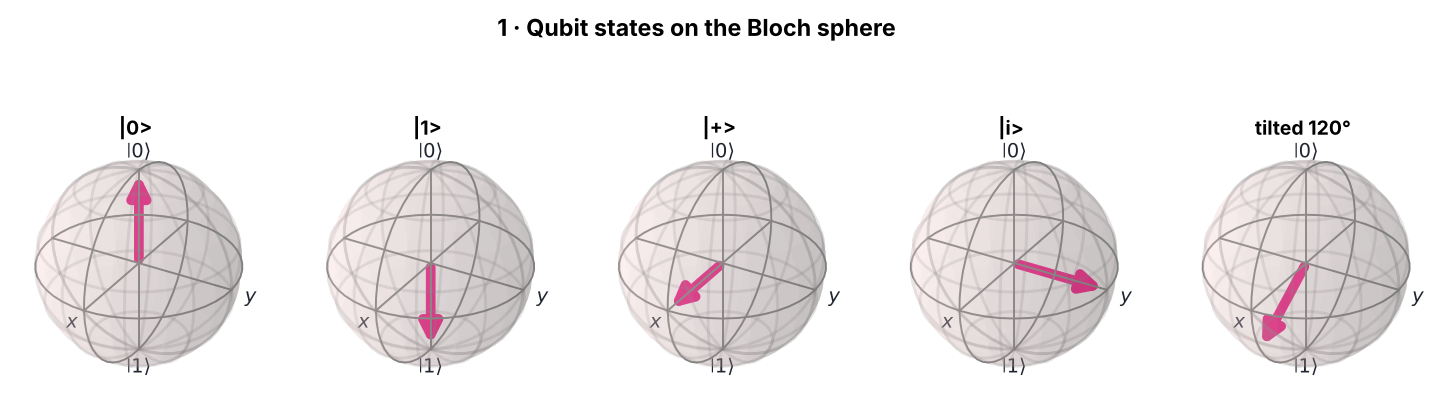

In [2]:
from concepts import c01_qubits
result = c01_qubits.run(save_plots=True)
for png in sorted((ROOT / 'outputs').glob('01_*.png')):
    display(Image(filename=str(png), width=900))

## 2. Superposition

H·H|0⟩ returns to 0 every time. A coin flipped twice does not. That difference is interference.


  2. SUPERPOSITION
  Weighted sums of states — and why interference is the real story

--- A. Hadamard on |0>: looks like a fair coin ------------------------
H|0> measured:      0: 1033  1: 967

--- B. Apply H twice: the 'coin' always lands on 0 --------------------
H H|0> measured:    0: 2000    <- interference
classical coin x2:  heads 51%                <- no interference
Math: H|+> = (H|0> + H|1>)/√2 = ½(|0>+|1>) + ½(|0>−|1>) = |0>. The two |1> paths cancel.

--- C. |+> vs |->: same Z statistics, different states ----------------
|+>  Z-basis: 0: 1011  1: 989           X-basis: 0: 2000


|->  Z-basis: 0: 1035  1: 965           X-basis: 1: 2000
The relative phase (+ or −) is invisible to one measurement but fully real.

--- D. 10 qubits in superposition = 1024 amplitudes, but ONE answer per shot 
5 shots of H^⊗10|0>: ['0100110000', '1101001010', '0010110010', '0001010010', '1011010010']
Each run returns a random bitstring. Reading out 'all answers at once' is impossible;
useful algorithms (see #5) choreograph interference so the RIGHT answer is likely.


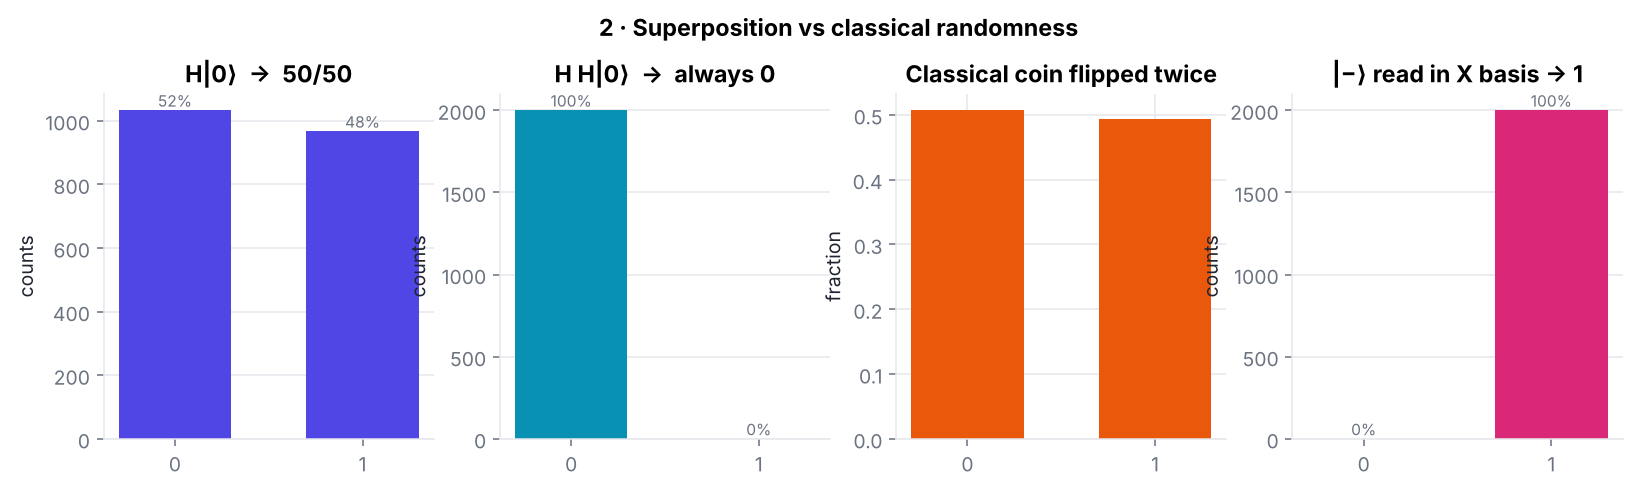

In [3]:
from concepts import c02_superposition
result = c02_superposition.run(save_plots=True)
for png in sorted((ROOT / 'outputs').glob('02_*.png')):
    display(Image(filename=str(png), width=900))

## 3. Entanglement

Bell states, the CHSH test (S ≈ 2.83 > 2), no-signaling, and teleportation.


  3. ENTANGLEMENT
  Correlations stronger than any classical system

--- A. Bell pair: outcomes always agree -------------------------------


phi+  00: 1012  11: 988
phi-  00: 1024  11: 976
psi+  01: 1012  10: 988
psi-  10: 1012  01: 988
phi± give only 00/11, psi± give only 01/10.


GHZ-5 (5-qubit cat state): 11111: 1016  00000: 984

--- B. No-signaling: Alice's half alone is pure noise -----------------
Alice's reduced density matrix:
 [[0.5 0. ]
 [0.  0.5]]
= I/2, a maximally mixed qubit. Nothing Bob does changes Alice's local statistics,
so entanglement transmits no information on its own (the infographic's 'instantly'
describes correlation, not communication).

--- C. CHSH Bell test — the actual proof of non-classicality ----------


  E(a,b) = +0.712
  E(a,b') = +0.705
  E(a',b) = +0.729
  E(a',b') = -0.714
S measured = 2.860   exact = 2.828   classical limit = 2.0
S > 2 -> no local hidden-variable model can explain this. (Max possible: 2.828)

--- D. Teleportation (uses entanglement + 2 classical bits) -----------


theta=    0°  Bob P(1)=0.000  expected 0.000


theta=   60°  Bob P(1)=0.254  expected 0.250


theta=   90°  Bob P(1)=0.510  expected 0.500


theta=  120°  Bob P(1)=0.756  expected 0.750


theta=  180°  Bob P(1)=1.000  expected 1.000
Bob only gets the state after Alice's 2 classical bits arrive -> no faster-than-light.


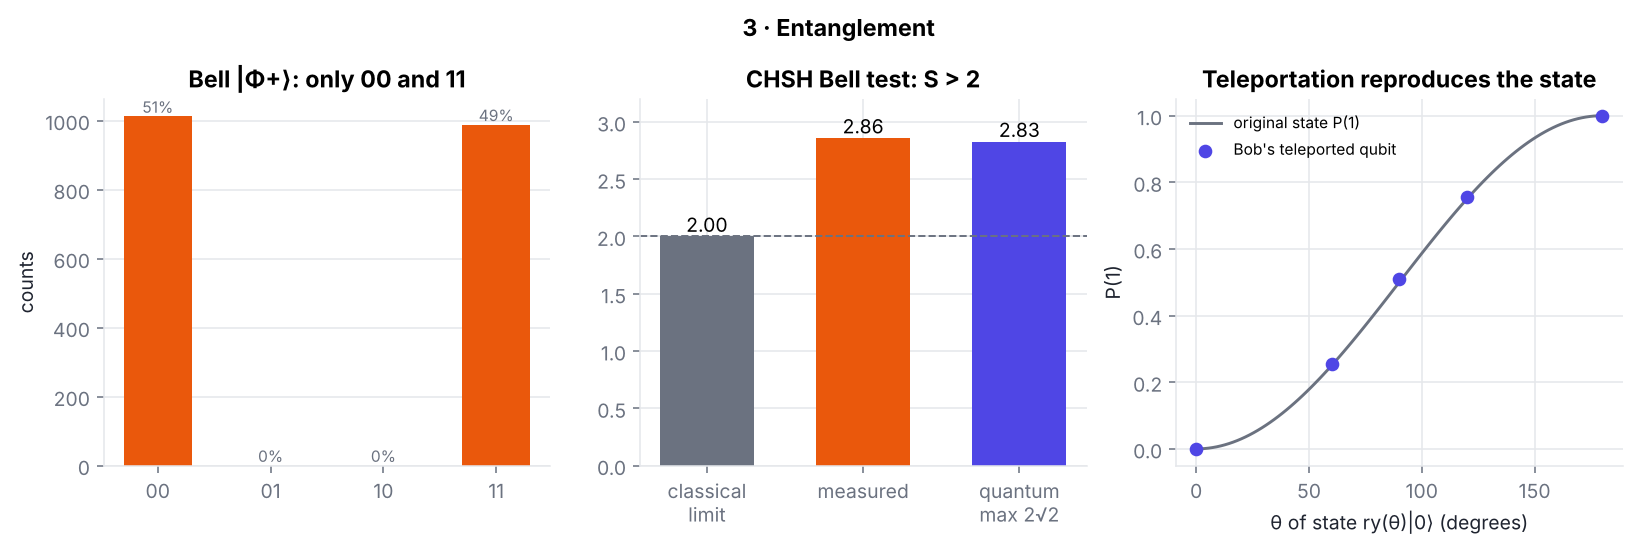

In [4]:
from concepts import c03_entanglement
result = c03_entanglement.run(save_plots=True)
for png in sorted((ROOT / 'outputs').glob('03_*.png')):
    display(Image(filename=str(png), width=900))

## 4. Quantum gates

Unitary matrices, gate identities, and the infographic's H→X bug.


  4. QUANTUM GATES
  Unitary, reversible building blocks

--- Gate matrices (all unitary) ---------------------------------------
X  (NOT, bit flip)       [0.00+0.00j, 1.00+0.00j]  [1.00+0.00j, 0.00+0.00j]   unitary=True
Y  (bit + phase flip)    [0.00+0.00j, -0.00-1.00j]  [0.00+1.00j, 0.00+0.00j]  unitary=True
Z  (phase flip)          [1.00+0.00j, 0.00+0.00j]  [0.00+0.00j, -1.00+0.00j]  unitary=True
H  (Hadamard)            [0.71+0.00j, 0.71+0.00j]  [0.71+0.00j, -0.71+0.00j]  unitary=True
S  (√Z, 90° phase)       [1.00+0.00j, 0.00+0.00j]  [0.00+0.00j, 0.00+1.00j]   unitary=True
T  (√S, 45° phase)       [1.00+0.00j, 0.00+0.00j]  [0.00+0.00j, 0.71+0.71j]   unitary=True
CNOT (4x4)               unitary=True

--- Identities the infographic implies but never shows ----------------
  ✓ H·H = I
  ✓ H·X·H = Z  (H swaps X and Z axes)
  ✓ S·S = Z
  ✓ T·T = S
  ✓ X·Y = iZ

--- CNOT truth table (q0 = control) -----------------------------------


  in 00 -> out 00
  in 01 -> out 11
  in 10 -> out 10
  in 11 -> out 01

--- Card 4, corrected -------------------------------------------------


X alone         -> 1: 1024
H then X        -> 0: 517  1: 507   (infographic claims {'1': 1024})
Why: H|0> = |+>, and X|+> = |+>. Flipping an equal superposition changes nothing.
H then Z then H -> 1: 1024   (this is the deterministic '1' they wanted)

--- Rotations are continuous: Rx(θ) gives P(1) = sin²(θ/2) ------------


  θ=    0°  P(1)=0.000  theory=0.000
  θ=   45°  P(1)=0.142  theory=0.146
  θ=   90°  P(1)=0.500  theory=0.500
  θ=  135°  P(1)=0.854  theory=0.854
  θ=  180°  P(1)=1.000  theory=1.000
  θ=  225°  P(1)=0.863  theory=0.854
  θ=  270°  P(1)=0.485  theory=0.500
  θ=  315°  P(1)=0.147  theory=0.146
  θ=  360°  P(1)=0.000  theory=0.000
Rx(π) equals X up to a global phase: True


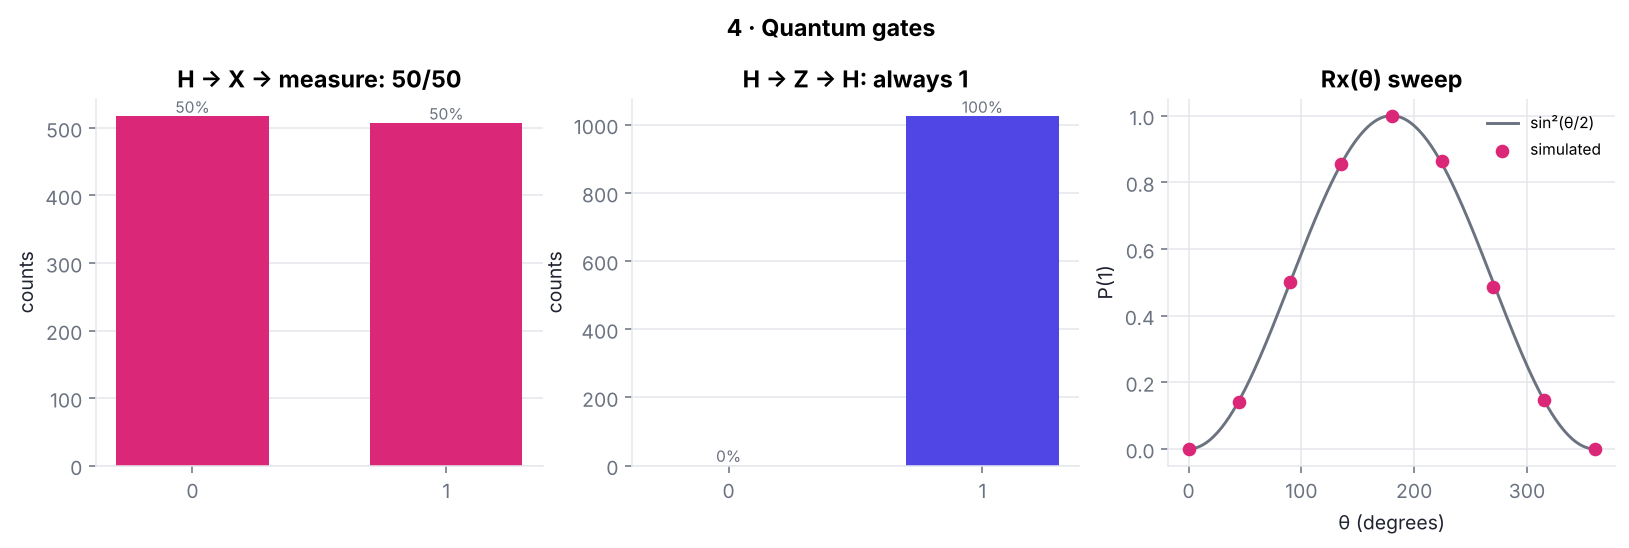

In [5]:
from concepts import c04_gates
result = c04_gates.run(save_plots=True)
for png in sorted((ROOT / 'outputs').glob('04_*.png')):
    display(Image(filename=str(png), width=900))

## 5. Quantum algorithms

Deutsch–Jozsa, Grover (with the overshoot curve), QFT period finding, VQE.


  5. QUANTUM ALGORITHMS
  Interference that makes right answers likely

--- A. Deutsch–Jozsa (n=4): constant or balanced in ONE query ---------
constant0  -> 0000: 500      => constant


constant1  -> 0000: 500      => constant
balanced   -> 1111: 500      => balanced
Classically you may need 2^(n-1)+1 = 9 queries to be certain.

--- B. Grover search --------------------------------------------------
2-qubit, marked |11>, corrected circuit -> 11: 1024


5-qubit (N=32), marked 10110, 4 iterations -> P(success)=1.000
Queries: Grover 4 vs classical average 16 (worst 31).


Success probability by iteration (too many iterations overshoots!):
  0:0.03  1:0.26  2:0.60  3:0.90  4:1.00  5:0.86  6:0.55  7:0.21  8:0.01  9:0.05  10:0.31  11:0.66  12:0.93

--- C. QFT period finding (core of Shor's algorithm) ------------------
Hidden period 4 over N=32 with offset 3 -> outcomes [0, 8, 16, 24]
All are multiples of 32/4 = 8. From the spacing we recover the period: 32/8 = 4.
Shor factors N by finding the period of a^x mod N exactly this way.

--- D. VQE: hybrid quantum–classical optimisation ---------------------


H = ZZ + 0.5·XI + 0.5·IX     VQE energy -1.41421   exact -1.41421   error 2.3e-09   (96 circuit evaluations)


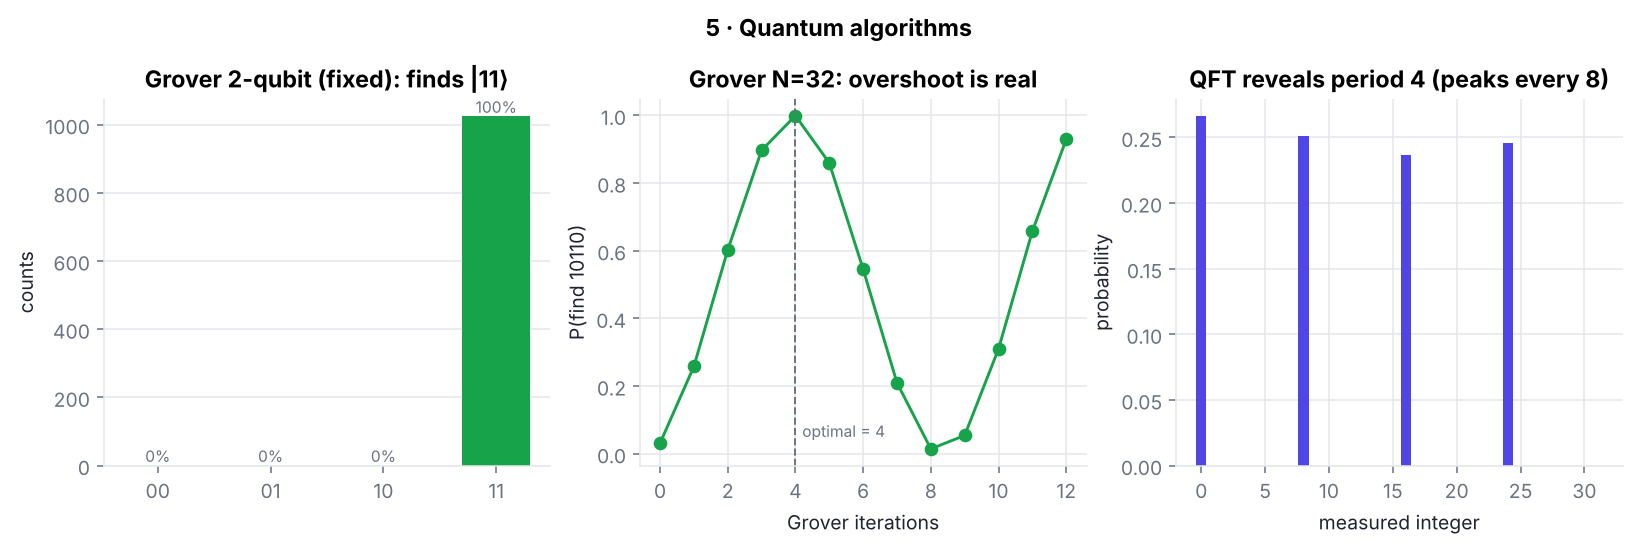

In [6]:
from concepts import c05_algorithms
result = c05_algorithms.run(save_plots=True)
for png in sorted((ROOT / 'outputs').glob('05_*.png')):
    display(Image(filename=str(png), width=900))

## 6. Quantum circuits

Gate-by-gate state evolution, metrics, compiling for real wiring, OpenQASM 3.


  6. QUANTUM CIRCUITS
  Gates on wires: the programs of quantum computing

--- A. The circuit ----------------------------------------------------
     ┌───┐     ┌─────────┐┌─┐   
q_0: ┤ H ├──■──┤ Rz(π/3) ├┤M├───
     └───┘┌─┴─┐└──┬───┬──┘└╥┘┌─┐
q_1: ─────┤ X ├───┤ X ├────╫─┤M├
          └───┘   └───┘    ║ └╥┘
c: 2/══════════════════════╩══╩═
                           0  1 

--- B. State vector after each gate -----------------------------------
start      +1.000+0.000j|00>
h(0)       +0.707+0.000j|00>  +0.707+0.000j|01>
cx(0,1)    +0.707+0.000j|00>  +0.707+0.000j|11>
rz(0)      +0.612-0.354j|00>  +0.612+0.354j|11>
x(1)       +0.612+0.354j|01>  +0.612-0.354j|10>
measured: 01: 1000  10: 1000   (Rz only adds phase, so probabilities stay 50/50)

--- C. Metrics --------------------------------------------------------
{'qubits': 2, 'depth': 4, 'size': 6, 'two_qubit_gates': 1, 'ops': {'measure': 2, 'h': 1, 'cx': 1, 'rz': 1, 'x': 1}}

--- D. Compiling for real wiring (5 qubits in a line, na

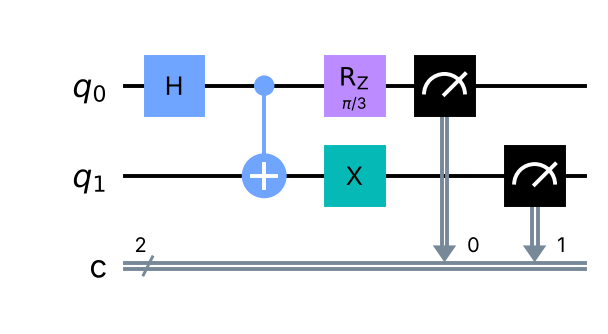

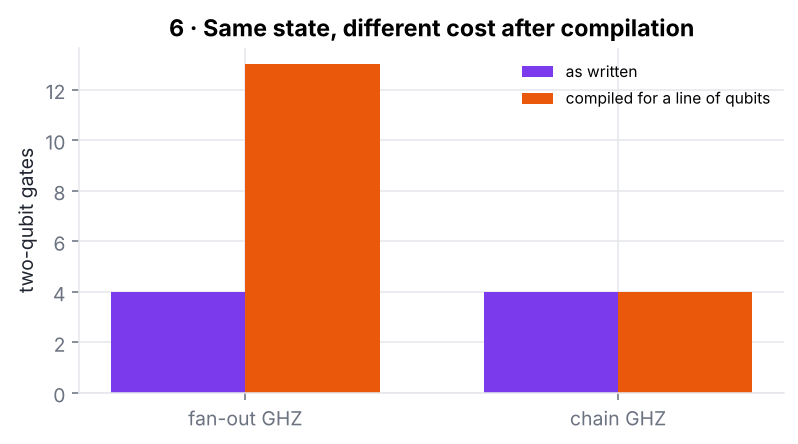

In [7]:
from concepts import c06_circuits
result = c06_circuits.run(save_plots=True)
for png in sorted((ROOT / 'outputs').glob('06_*.png')):
    display(Image(filename=str(png), width=900))

## 7. Quantum hardware

A real IBM Heron calibration snapshot, ideal vs noisy GHZ, measuring T1 and T2.


  7. QUANTUM HARDWARE
  Physical qubits, real noise, real constraints

--- A. Vital signs of an IBM Heron chip (calibration snapshot) --------


device fake_fez  ·  156 qubits  ·  native gates ['cz', 'rz', 'sx', 'x']
median T1 145 µs   median T2 88 µs   CZ time 84 ns
median errors: single-qubit 2.3e-04   CZ 3.9e-03   readout 7.6e-03
=> about 1047 CZ durations fit inside one T2, but at a 0.39% CZ error rate a circuit
   has <50% chance of being error-free after ~178 CZ gates. Gate errors, not coherence time, are the binding limit.

--- B. Compilation onto the chip --------------------------------------


Bell circuit compiled -> ops {'rz': 6, 'sx': 3, 'measure': 2, 'cz': 1}, physical qubits [0, 1]
noisy Bell counts: 00: 979  11: 975  10: 25  01: 21  (01/10 shouldn't exist — that's noise)

--- C. Ideal vs noisy as circuits grow (GHZ-n) ------------------------


GHZ-2   ideal P(all-0 or all-1) = 1.000   on noisy chip = 0.977


GHZ-4   ideal P(all-0 or all-1) = 1.000   on noisy chip = 0.951


GHZ-6   ideal P(all-0 or all-1) = 1.000   on noisy chip = 0.935


GHZ-8   ideal P(all-0 or all-1) = 1.000   on noisy chip = 0.883


GHZ-10  ideal P(all-0 or all-1) = 1.000   on noisy chip = 0.880


GHZ-12  ideal P(all-0 or all-1) = 1.000   on noisy chip = 0.849

--- D. Decoherence: measure T1 and T2 yourself ------------------------


T1 set 100 µs -> fitted 99.9 µs  (|1> decays to |0>)
T2 set 80 µs -> fitted 83.3 µs  (superposition loses phase)

--- E. Hardware landscape ---------------------------------------------
Superconducting  IBM, Google, Rigetti           + fast gates (tens of ns), mature fabrication
                                                − needs ~10–15 mK dilution fridges; short coherence
Trapped ions     Quantinuum, IonQ               + highest gate fidelities, all-to-all connectivity
                                                − slower gates (µs); scaling ion chains
Neutral atoms    QuEra, Pasqal, Atom Computing  + hundreds–thousands of atoms, reconfigurable layouts
                                                − slower cycles; atom loss
Photonic         PsiQuantum, Xanadu             + photons barely decohere; telecom-compatible
                                                − photon loss; deterministic 2-qubit gates are hard; detectors often cryogenic
Spin qubits      Intel, Diraq      

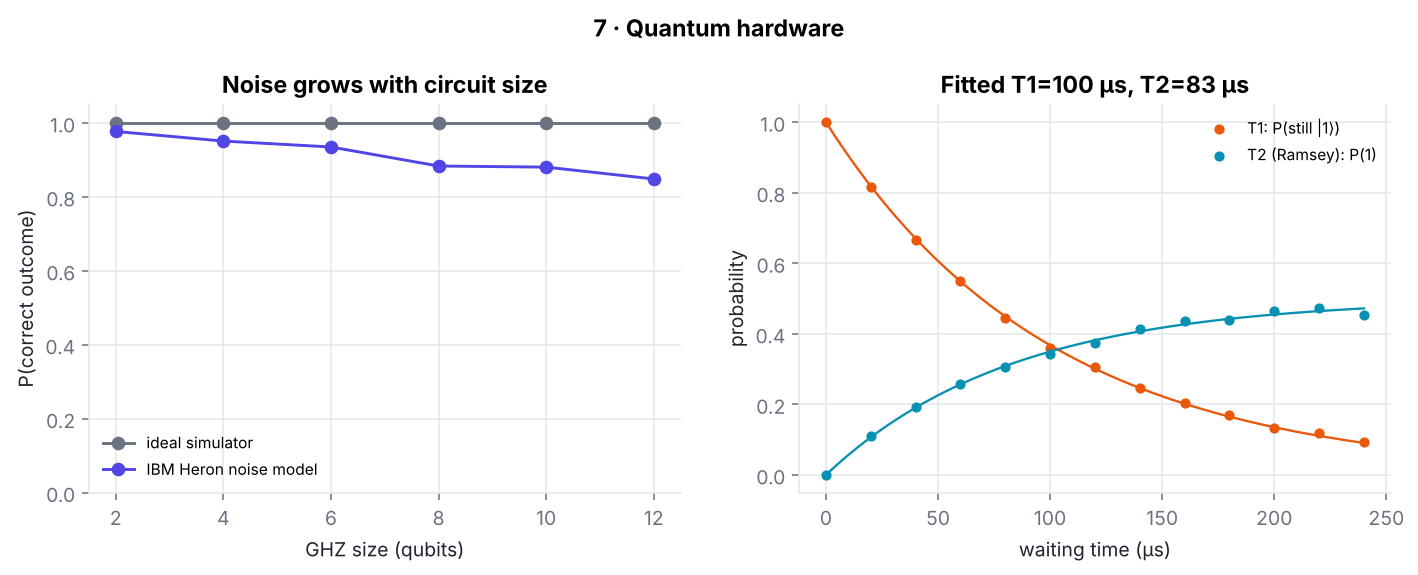

In [8]:
from concepts import c07_hardware
result = c07_hardware.run(save_plots=True)
for png in sorted((ROOT / 'outputs').glob('07_*.png')):
    display(Image(filename=str(png), width=900))

## 8. Quantum error correction

A working bit-flip code, the phase-flip code, and threshold behaviour.


  8. QUANTUM ERROR CORRECTION
  Redundancy + parity checks, without looking at the data

--- A. Bit-flip code: every single X error is corrected ---------------


logical |0>         no error: 0% wrong  X on d0: 0% wrong  X on d1: 0% wrong  X on d2: 0% wrong


logical |1>         no error: 0% wrong  X on d0: 0% wrong  X on d1: 0% wrong  X on d2: 0% wrong


logical ry(1.1)|0>  no error: 0% wrong  X on d0: 0% wrong  X on d1: 0% wrong  X on d2: 0% wrong

--- B. ...but a phase (Z) error slips through the bit-flip code -------
Z error on d1, logical ry(π/2)|0>: 100% wrong

--- C. Phase-flip code (same idea in the X basis) fixes Z errors ------


no error: 0% wrong  Z on d0: 0% wrong  Z on d1: 0% wrong  Z on d2: 0% wrong
Shor's 9-qubit code nests both codes to fix any single-qubit error; surface codes
generalise the parity-check idea to a 2D grid that scales.

--- D. Threshold behaviour: distance-d repetition code under noise ----
d=1: p=0.01→0.0097  p=0.05→0.0503  p=0.10→0.0920  p=0.20→0.2045  p=0.30→0.3100  p=0.40→0.3990  p=0.50→0.4975


d=3: p=0.01→0.0008  p=0.05→0.0057  p=0.10→0.0297  p=0.20→0.0983  p=0.30→0.2092  p=0.40→0.3500  p=0.50→0.5015
d=5: p=0.01→0.0000  p=0.05→0.0015  p=0.10→0.0067  p=0.20→0.0583  p=0.30→0.1600  p=0.40→0.3292  p=0.50→0.4988


d=7: p=0.01→0.0000  p=0.05→0.0000  p=0.10→0.0032  p=0.20→0.0315  p=0.30→0.1268  p=0.40→0.2840  p=0.50→0.5040
Below p=0.5 (this code's threshold), each step up in distance suppresses errors further.
Real codes also have to cope with faulty syndrome measurements, which pushes practical
thresholds down to roughly 1% for the surface code.


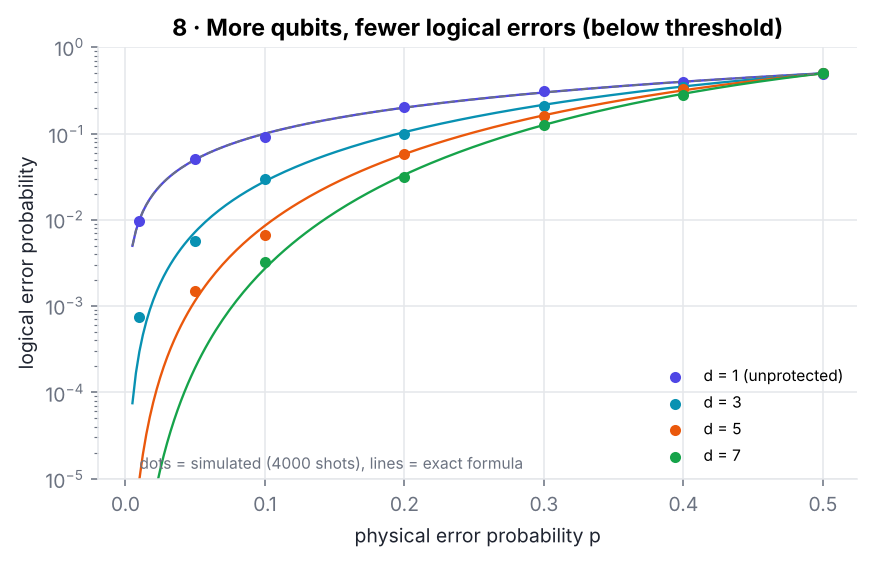

In [9]:
from concepts import c08_error_correction
result = c08_error_correction.run(save_plots=True)
for png in sorted((ROOT / 'outputs').glob('08_*.png')):
    display(Image(filename=str(png), width=900))

## 9. Quantum advantage

The 2ⁿ memory wall, measured simulation time, and cross-entropy benchmarking.


  9. QUANTUM ADVANTAGE
  Beating the best classical method — on specific tasks

--- A. The classical wall: memory to store an n-qubit state -----------
   10 qubits ->           16 KiB
   20 qubits ->           16 MiB
   30 qubits ->           16 GiB
   40 qubits ->           16 TiB
   50 qubits ->           16 PiB
   53 qubits ->          128 PiB
   60 qubits ->           16 EiB
  100 qubits ->    2.0e+31 bytes
A laptop tops out near 30 qubits; ~50 qubits needs more memory than any supercomputer has
(clever tensor-network methods dodge this for some circuits — which is why claims get contested).

--- A2. Measured on this machine: statevector simulation time ---------


  12 qubits:       3.5 ms
  14 qubits:       9.3 ms
  16 qubits:      13.9 ms
  18 qubits:      46.0 ms
  20 qubits:     194.7 ms
  22 qubits:     824.6 ms
  24 qubits:    3804.2 ms
Each extra qubit multiplies runtime by ~2.08× (ideal: 2×).

--- B. Counting queries: Grover vs classical search -------------------
  N=              16: classical ~               8 checks   Grover ~         3
  N=           1,000: classical ~             500 checks   Grover ~        24
  N=       1,000,000: classical ~         500,000 checks   Grover ~       785
  N=1,000,000,000,000: classical ~ 500,000,000,000 checks   Grover ~   785,398
Quadratic, not exponential — and error-correction overhead eats much of it in practice.

--- C. Cross-entropy benchmarking on random circuits (the 2019 method) 


8 qubits, 10 cycles:
  ideal quantum device   F_XEB = +1.082
  IBM Heron noise model  F_XEB = +0.731
  random guessing        F_XEB = -0.003
A device 'wins' if it reaches a positive F_XEB at a size no classical computer can
reproduce in reasonable time. Noise drags F_XEB toward 0 — hence module 8.

--- D. Timeline (claims are task-specific and get challenged) ---------
  1994      Shor's algorithm: factoring in polynomial time on a quantum computer — the theoretical spark.
  1996      Grover's algorithm: quadratic speed-up for unstructured search.
  2019      Google Sycamore (53 qubits) sampled random circuits in ~200 s and claimed ~10,000 years classically. IBM countered that a supercomputer with enough disk could do it in ~2.5 days.
  2022      Tensor-network methods reproduced the 2019 sampling task classically on GPUs in hours, showing that advantage claims are a moving target as classical algorithms improve.
  2024      Google Willow (105 qubits): logical error rates fell as the s

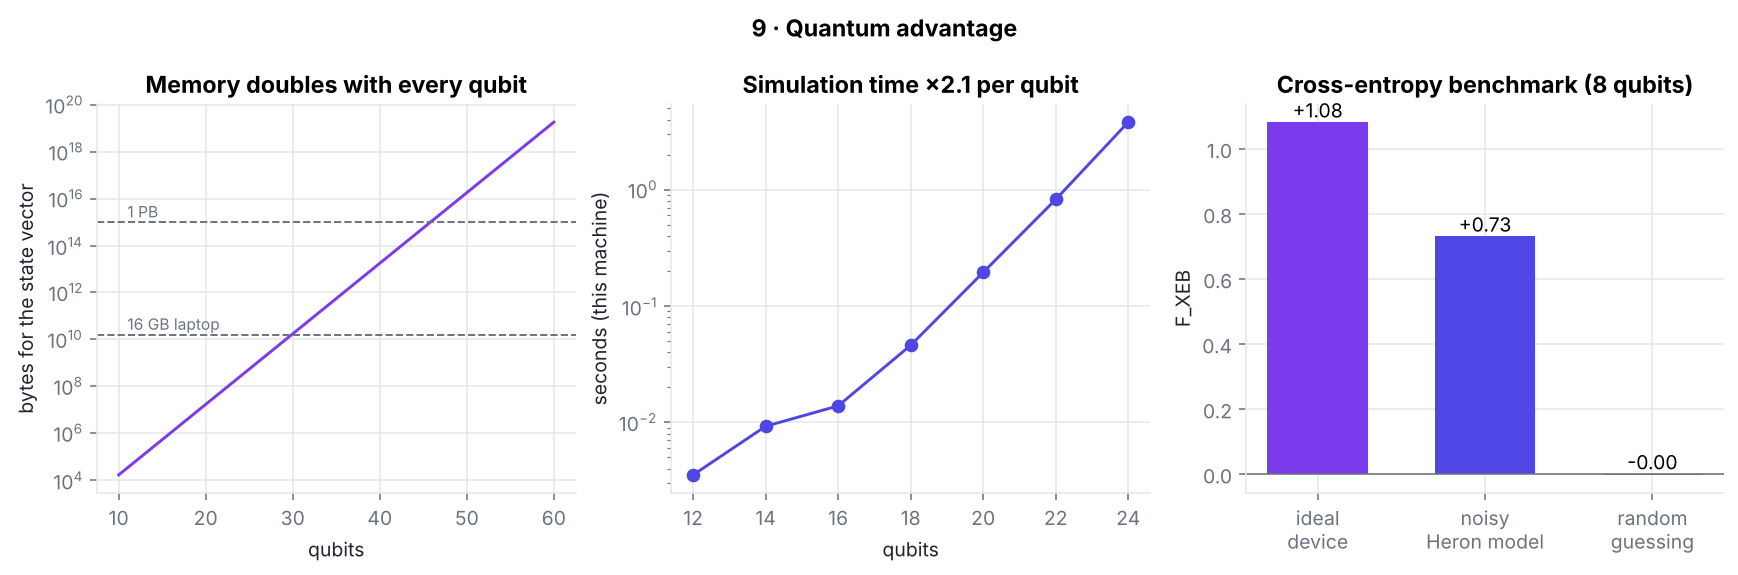

In [10]:
from concepts import c09_advantage
result = c09_advantage.run(save_plots=True)
for png in sorted((ROOT / 'outputs').glob('09_*.png')):
    display(Image(filename=str(png), width=900))

## Where next

- `CORRECTIONS.md` — what the infographic gets wrong, with evidence.
- `exercises/` and `python grade.py` — nine autograded take-home exercises.
- `web/quantum-lab.html` — the same experiments, interactive, in eight languages.
- `CURRICULUM.md` — a nine-session course built on this code.